# 21 The I2t winding estimate

Notebook 19 graded the winding thermometer that shipped in `estimator::thermal`, a resistance
thermometer with seats, reference windows and a carry model between them. It read the winding to
about a degree when it worked, and it took 1250 lines of firmware and four kernel stages to do it.
I have since decided that a degree is not what the firmware needs. What it needs is to keep the
winding under its limit, and showing a winding temperature is a nice extra. So the thermometer is
coming out, and what replaces it is one multiply.

The kernel already keeps an I2t budget for the current limit, a leaky sum of the current squared.
That sum is the winding's excess temperature in disguise. Add it to the board NTC with one user
constant and you have a winding estimate. This notebook replays that estimate over the heating
holds already on disk, fits its two constants for the two places the NTC can sit, and grades it
against the winding read through its own copper. Nothing here needed the bench.

If you are short on time, here is the quick version. With the NTC on the can (where it sits on a
swap board) the estimate holds the winding within about 4 C over a ten minute hold at the rating,
with a 16 s leak. With the NTC on a board in room air (the dev board) it wants a 124 s leak, gets
65.5 s from the firmware's cap, and still holds within about 4 C. The constants are in section 6.

## Picking a rig

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import oscnb
from oscnb import boards, datasets, servos, thermal as th, thermometer as tm, heating as ht, i2t

# Both datasets came off rev 2A board #1 with the bench MG90. The thermometer dataset carries no
# sense block (notebook 19 says why), so the board is named by hand, as there.
board, servo = boards.BOARDS["dev-v006-2A"], servos.SERVOS["mg90-a"]
rig = oscnb.Rig(board, servo).show()

DS = datasets.load("mg90-a__dev-v006-2A__dps__thermometer")   # the two `osc ident thermal` holds (DPS, board NTC logged)
H = datasets.load("mg90-a__dev-v006-2A__2s__heating")         # the locked-rotor hold (2S, bead on the can, NTC dead)
IX = tm.index(DS).set_index("capture")

K_CU = th.T0_CU                                               # copper: R is proportional to (234.5 + T)
OHM = board.v_term_per_count / board.a_per_count              # ohm per vcount/ccount
pd.set_option("display.width", 160)

Vorpal MG90 clone, unit A on osc-dev-v006 rev 2A, board #1

  board: Rs1 60 mOhm; bare OPA with Rf 6k4 / Rg 430 (G 14.884), Cc 22 pF, Co1 DNP. Terminal taps Rv1/Rv3 6k4 over Rv2/Rv4 1k6 with Cv1/Cv2 100 pF, bottoms and caps returned to VB from Rb1 430 / Rb2 100 (773 counts nominal, about 81 ohm source, so VB rises with the leg current under drive). VSNS 6k4/1k6 to GND, unbiased, Cv3 100 pF. A 2A capture's sense block differs from board D's in gain_milli and both divider legs. Nothing in the block carries the bias or VSNS parts, or which 2A unit took the capture, so every 2A board shares this entry. Board #1 had Rv3 open for the grid-3r7 2S session: in that dataset tap B reads the VB node instead of terminal B, so only tap A, the rail and the current are graded there. Rv3 is repaired, and a dataset captured with it fitted reads both taps. Floors 64/93 ticks: the current at 3% with the settle gain on top (nb10 sec 8), the terminals from the grid ladder with tap B sampled 37 ticks before 

value
where            quantity                                           unit                          
board            converter step                                     mV per count            0.8057
                 terminal divider ratio r                                                   5.0000
                 terminal difference                                mV per count            4.0283
                 terminal bias VB                                   mV                    622.6415
                                                                    counts                772.8302
                 driven-low terminal reads                          counts                618.2642
                 motor current                                      mA per count            0.9022
                                                                    counts per A         1108.4521
                 shunt                                              mOhm                   60.0000
                 amplifier gain                                     x                      14.8840
                 rail tap ratio                                                             5.0000
                 sample rate                                        samples per ms         20.0000
                 current settled from                               % duty                  5.3333
                 voltage settled from                               % duty                  7.7500
servo            pot intercept                                      counts                209.0000
                 pot slope                                          counts per degree      19.7600
                 envelope low                                       counts (15.74 deg)    520.0224
                 envelope high                                      counts (168.59 deg)  3540.3384
                 runway                                             counts               3020.3160
                 seek guard low                                     counts                520.0000
                 seek guard high                                    counts               3540.0000
servo (measured) gear_ratio_measured [308.053, 308.053] mechanic... :1                    308.0533
                 ripple_order_measured [6, 6] teardown, 3-slot b... per motor rev           6.0000
                 r_winding_measured [4.49, 4.98] bringup capture... Ohm                     4.8900
                 ke_ripple_measured [1.284, 1.306] nb09 sec 3, s... mV per ripple Hz        1.2950
                 pot_scale_measured [19.7, 19.85] nb09 sec 10, r... counts/deg             19.7600
                 travel_measured [178.67, 189.18] nb09 sec 10, p... deg                   184.2200
                 low_stop_after_stall_measured [232, 236] hand s... counts                232.0000
                 backlash_measured [1.25, 1.5] nb09 sec 4, rever... ripple cycles           1.4800

## 1. The estimate

Every 16 ms (the kernel's SLOW period) the I2t budget leaks the square of the held current into a
heat state. In the firmware's integers that is

$$\text{heat} \mathrel{+}= (i^2 - \text{heat}) \gg s$$

with $i$ in current counts and $s$ the leak as a power of two of SLOW periods, so the time constant
is $\tau = 16\,\text{ms} \cdot 2^s$. The user writes `thermal_tau_ms` and the firmware rounds it to
the nearest octave, at most $2^{12}$ periods, which is 65.5 s. The estimate is then

$$\hat T_w = T_\text{ntc} + k \cdot \text{heat}$$

where $k$ is a rise constant in centi-C per count squared, carried as Q0.16. Physically $k$ is the
thermal resistance from the winding to wherever the NTC sits, times the winding's resistance, times
the square of the board's amps per count, so a user who knows the motor's K/W can write it, and a
user who does not can run the heating hold this notebook replays.

What the one leak cannot do is follow two time constants. The winding over the can is fast (tens
of seconds) and the can over the air is slow (notebook 18's 129 s). With the NTC on the can the
leak only has to carry the fast node. With the NTC on a board in room air it has to carry both
with one number, and section 3 shows what that costs.

`oscnb.i2t` is the replay. `heat` runs the kernel's integer arithmetic exactly (the guard bits, the
capped square, the arithmetic shift), `ewma` is the same leak in floats at any time constant, and
`grid` puts a capture's current polls on the 16 ms grid the way the kernel sees them, holding the
last poll.

In [2]:
# the leak octaves the firmware can run, and the time constant each one lands on
octaves = pd.DataFrame({"shift": range(6, 13)})
octaves["tau_s"] = [i2t.tau_s(s) for s in octaves["shift"]]
octaves["thermal_tau_ms"] = (octaves.tau_s * 1000).astype(int)
display(octaves.set_index("shift").T)
print(f"the boot default 4096 ms runs at shift {i2t.tau_shift(4.096)} ({i2t.tau_s(i2t.tau_shift(4.096)):.1f} s)")

shift,6,7,8,9,10,11,12
tau_s,1.024,2.048,4.096,8.192,16.384,32.768,65.536
thermal_tau_ms,1024.000,2048.000,4096.000,8192.000,16384.000,32768.000,65536.000


the boot default 4096 ms runs at shift 8 (4.1 s)


## 2. The holds and the truth

Three holds at the current limit sit on disk, all on the same motor and board.

- `thermal/capture-1` and `thermal/capture-2` of the thermometer dataset. 480 s seated at the low
  stop at 280 counts on the DPS, the identification aggregates (current, terminal difference, duty)
  every 22 ms, the K bead on the can, and for capture-2 the board NTC in the polls. Capture-1 has no
  NTC in its polls (the tool did not log it yet), only in the rest log before the hold.
- `hold/capture-1` of the heating dataset. A 600 s locked-rotor hold at the low stop on the 2S pack,
  the same aggregates, the bead on the can in every poll, the board NTC dead that night.

The truth is the winding read through its own copper. The aggregates give the winding's resistance
as $R = d \cdot v_\text{diff} / i$ through the board's volts and amps per count ($d$ the applied duty),
the same ratio `osc ident resistance` reads. I take the reference $R_\text{ref}$ over the window 1 to
3 s into the hold, the way the shipped thermometer did (the brush contact settles through the first
second), and read the winding from then on as

$$T_w = T_{w0} + \left(\frac{R}{R_\text{ref}} - 1\right)(234.5 + T_{w0})$$

with $T_{w0}$ the can at the start of the hold, since the servo rested for ten minutes before each
and winding, can and board sit at one temperature then. Notebook 19 measured the can below the
board NTC by 2.0 to 2.75 C at rest and could not say which of the two is off. I use the can as the
winding's start and the NTC as the firmware's base, which is what the firmware will do.

The two placements come out of the same holds. The excess over the can, $T_w - T_\text{can}$, is what
an NTC on the can would have to carry. The excess over the board NTC, $T_w - T_\text{ntc}$, is what
the dev board's NTC has to carry. Only capture-2 can grade the second.

In [3]:
def ident_hold(capture):
    # The `osc ident thermal` hold: aggregates in anchor.csv.gz (t_ms from the run's start), the
    # tool's polls in anchor_snapshots.csv.gz (host_ms), the bead in meter.csv.gz (unix).
    a = tm._csv(DS.path / capture / "anchor.csv.gz")
    a["t"] = a.t_ms / 1000
    a["r"] = (a.duty_q15.abs() / 32767) * (a.vdiff / a.i) * OHM      # the aggregate R, ohm
    s = tm._csv(DS.path / capture / "anchor_snapshots.csv.gz")
    s["t"] = s.host_ms / 1000
    m, u0 = tm.meter(DS, capture), IX.loc[capture, "unix0"]
    tt = np.arange(2.0, 480.0, 1.0)                                    # the truth on a 1 s grid
    r = np.array([a[(a.t >= x - 0.5) & (a.t < x + 0.5)].r.mean() for x in tt])
    r_ref = a[(a.t >= 1) & (a.t < 3)].r.mean()
    can = tm.can_at(m, u0 + tt, 3.0)
    tw0 = tm.can_at(m, u0, 5.0)
    ntc = (np.array([s[(s.t >= x - 2.5) & (s.t < x + 2.5)].t_ntc_cc.mean() / 100 for x in tt])
           if "t_ntc_cc" in s else None)
    tg, ig = i2t.grid(a.t.to_numpy(), a.i.abs().to_numpy(), 0.0, 481.0)   # the kernel's view of the current
    p = float((a.r * (a.i * board.a_per_count) ** 2).mean())
    return dict(tt=tt, r=r, r_ref=r_ref, tw0=tw0, tw=tw0 + (r / r_ref - 1) * (K_CU + tw0),
                can=can, ntc=ntc, tg=tg, ig=ig, i=float(a.i.abs().mean()), p=p)


def locked_hold():
    # The heating dataset's locked-rotor hold: polls with the aggregates and the bead inline.
    h = ht.hold(H, "hold/capture-1", board)
    h = h[h.phase == "hold"]
    t0 = h.t_s.min()
    tt = np.arange(t0 + 2.0, h.t_s.max(), 1.0)
    r = np.array([h[(h.t_s >= x - 0.5) & (h.t_s < x + 0.5)].r_agg.mean() for x in tt])
    r_ref = h[(h.t_s >= t0 + 1) & (h.t_s < t0 + 3)].r_agg.mean()
    can = np.array([h[(h.t_s >= x - 3) & (h.t_s < x + 3)].can_c.mean() for x in tt])
    tw0 = h[h.t_s < t0 + 5].can_c.mean()
    tg, ig = i2t.grid(h.t_s.to_numpy(), h.i_hat.abs().to_numpy(), t0, h.t_s.max())
    return dict(tt=tt - t0, r=r, r_ref=r_ref, tw0=tw0, tw=tw0 + (r / r_ref - 1) * (K_CU + tw0),
                can=can, ntc=None, tg=tg - t0, ig=ig, i=float(h.i_hat.abs().mean()),
                p=float((h.r_agg * h.i_a ** 2).mean()))


RUNS = {"thermal/capture-1": ident_hold("thermal/capture-1"),
        "thermal/capture-2": ident_hold("thermal/capture-2"),
        "heating hold": locked_hold()}

rows = []
for name, R in RUNS.items():
    rows.append({"run": name, "i counts": R["i"], "P W": R["p"], "R_ref ohm": R["r_ref"],
                 "T_w0 C": R["tw0"], "winding rise C": R["tw"][-1] - R["tw0"],
                 "can rise C": R["can"][-1] - R["can"][0],
                 "NTC rise C": np.nan if R["ntc"] is None else R["ntc"][-1] - R["ntc"][0],
                 "end excess over can C": R["tw"][-1] - R["can"][-1],
                 "end excess over NTC C": np.nan if R["ntc"] is None else R["tw"][-1] - R["ntc"][-1]})
HOLDS = pd.DataFrame(rows).set_index("run")
display(HOLDS.round(3))

,i counts,P W,R_ref ohm,T_w0 C,winding rise C,can rise C,NTC rise C,end excess over can C,end excess over NTC C
run,,,,,,,,,
thermal/capture-1,266.115,0.269,4.486,25.600,11.564,8.100,NaN,3.464,NaN
thermal/capture-2,262.555,0.260,4.457,25.400,11.495,8.200,1.244,3.295,7.53
heating hold,264.816,0.274,4.595,27.015,11.123,6.485,NaN,4.638,NaN


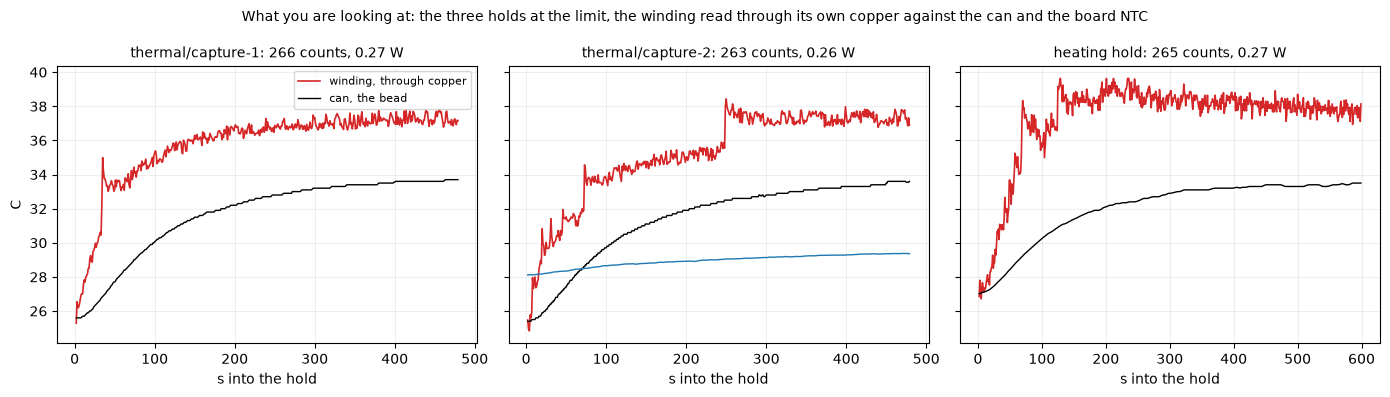

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, R) in zip(axes, RUNS.items()):
    ax.plot(R["tt"], R["tw"], color="tab:red", lw=1.2, label="winding, through copper")
    ax.plot(R["tt"], R["can"], color="k", lw=1, label="can, the bead")
    if R["ntc"] is not None:
        ax.plot(R["tt"], R["ntc"], color="tab:blue", lw=1, label="board NTC")
    ax.set_title(f"{name}: {R['i']:.0f} counts, {R['p']:.2f} W", fontsize=10)
    ax.set_xlabel("s into the hold")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("C")
axes[0].legend(fontsize=8)
fig.suptitle("What you are looking at: the three holds at the limit, the winding read through its own copper "
             "against the can and the board NTC", fontsize=10)
plt.tight_layout()
plt.show()

Three things stand out before any fit. The copper reading steps, by 1 to 1.5 % of R in a second,
once or twice per hold (capture-2's step at 248 s is the one the old thermometer's gate flagged as
G3 in the dataset notes). Notebook 19 traced steps like these to the brush contact, and a contact
step reads as 2.5 to 4 C of winding that is not there. They stay in the truth here, because I have
no honest way to take them out, and they set a floor under any grade. The winding's excess over
the can peaks early, 6 to 9 C in the first minute, and then falls back to 3 to 5 C while the can
keeps rising, which a two-node plant does not do, its fast node rises and stays. And the first ten
seconds rise far faster than the winding's heat capacity allows. Section 7 takes the last two up.
For the grade they matter in one way, the early peak is where an estimate with one leak reads
coldest.

On the dev board the NTC rose 1.25 C over 480 s while the winding rose 11.5 C. The board's own NTC
is nearly a room thermometer there, so the estimate's rise term has to carry almost everything.

## 3. Fitting k and tau

For each run and each base I run the heat at every leak octave the firmware can take, and once
more in floats at a free time constant, and fit the one $k$ that best matches the truth excess over
the hold by least squares. The table reads the residual sd and the signed extremes of the error
(estimate minus truth), in C. Negative is the estimate reading cold, which is the side protection
cares about.

In [5]:
def fits(name, base):
    R = RUNS[name]
    b = R[base]
    if b is None:
        return []
    x = R["tw"] - b                                          # the truth excess over this base, C
    out = []
    for shift in range(6, 13):
        hq = i2t.heat(R["ig"].astype(np.int64), shift)       # the kernel's integer heat state
        hat = np.interp(R["tt"], R["tg"], hq)
        k, sd = i2t.fit_k(hat, x * 100)
        lo, hi, rms = i2t.grade(k * hat / 100, x)
        out.append(dict(run=name, base=base, shift=shift, tau_s=i2t.tau_s(shift), k=k, k_q16=i2t.k_q16_of(k),
                        sd_C=sd, cold_C=lo, warm_C=hi))
    best = None
    for tau in np.geomspace(4, 400, 80):                     # the free leak, floats
        hat = np.interp(R["tt"], R["tg"], i2t.ewma(R["ig"] ** 2, tau, i2t.SLOW_S))
        k, sd = i2t.fit_k(hat, x * 100)
        if best is None or sd < best[1]:
            best = (tau, sd, k, hat)
    lo, hi, rms = i2t.grade(best[2] * best[3] / 100, x)
    out.append(dict(run=name, base=base, shift="free", tau_s=best[0], k=best[2], k_q16=i2t.k_q16_of(best[2]),
                    sd_C=best[1], cold_C=lo, warm_C=hi))
    return out


FITS = pd.DataFrame(sum((fits(n, b) for n in RUNS for b in ("can", "ntc")), []))
print(FITS.round({"tau_s": 1, "k": 5, "sd_C": 2, "cold_C": 2, "warm_C": 2}).to_string())

                  run base shift  tau_s        k  k_q16  sd_C  cold_C  warm_C
0   thermal/capture-1  can     6    1.0  0.00577    378  0.84   -3.98    3.62
1   thermal/capture-1  can     7    2.0  0.00579    380  0.81   -3.93    3.11
2   thermal/capture-1  can     8    4.1  0.00583    382  0.76   -3.88    2.55
3   thermal/capture-1  can     9    8.2  0.00588    386  0.69   -3.88    1.57
4   thermal/capture-1  can    10   16.4  0.00597    391  0.69   -4.30    1.02
5   thermal/capture-1  can    11   32.8  0.00608    398  0.89   -5.25    1.10
6   thermal/capture-1  can    12   65.5  0.00631    413  1.25   -6.27    1.25
7   thermal/capture-1  can  free   12.1  0.00593    388  0.67   -4.04    0.99
8   thermal/capture-2  can     6    1.0  0.00556    365  0.79   -2.17    4.33
9   thermal/capture-2  can     7    2.0  0.00558    366  0.76   -2.14    3.47
10  thermal/capture-2  can     8    4.1  0.00562    368  0.71   -2.10    2.66
11  thermal/capture-2  can     9    8.2  0.00567    372  0.65   

With the NTC on the can the free leak lands at 12 to 33 s across the three runs and the residual is
0.6 to 1.1 C. The octaves either side of it cost little. $k$ comes out at 0.0057 to 0.0079 centi-C
per count squared, the locked hold reading a third higher than the two ident holds. Through
$k = R_{wc} \cdot R \cdot (\text{A/count})^2$ that is 15 to 21 C/W from the winding to the can,
which is under the 28 to 45 C/W notebook 18 bracketed (section 7).

With the NTC on the dev board the free leak wants 124 s, which is the can's slow mode showing
through, and the firmware caps the leak at 65.5 s. At the cap the residual goes from 0.7 to 1.0 C
and the cold extreme from 2.5 to 2.1 C. The cap costs nothing worth a wider field.

The physical check: notebook 18's 60 to 71 C/W from the winding to the air gives $k$ of 0.023 to
0.027 for the dev board, and the fit says 0.011 to 0.012. The NTC on the dev board warmed 1.25 C in
the hold, so it is not quite a room thermometer, but that explains a tenth of the gap, not half.
The copper truth reads the winding lower than the model expects at this power, and section 7 says
what could do that.

In [6]:
# the constants I will carry: the leak octave each placement runs at, and k from the fits at it
CAN_SHIFT, NTC_SHIFT = 10, 12
can_k = FITS[(FITS.base == "can") & (FITS["shift"] == CAN_SHIFT)].set_index("run").k
ntc_k = FITS[(FITS.base == "ntc") & (FITS["shift"] == NTC_SHIFT)].set_index("run").k
print("NTC on the can, shift", CAN_SHIFT, f"({i2t.tau_s(CAN_SHIFT):.1f} s): k per run")
print(can_k.round(5).to_string())
print("NTC on the board in air, shift", NTC_SHIFT, f"({i2t.tau_s(NTC_SHIFT):.1f} s): k per run")
print(ntc_k.round(5).to_string())

# protection wants the estimate on the warm side, so the shipped k is the largest the runs gave
K_CAN, K_NTC = float(can_k.max()), float(ntc_k.max())
for label, k, r_ohm in (("can", K_CAN, HOLDS["R_ref ohm"].mean()), ("board NTC", K_NTC, HOLDS["R_ref ohm"].mean())):
    r_th = k / (100 * r_ohm * board.a_per_count ** 2)
    print(f"shipped k, NTC on the {label}: {k:.5f} cC/count^2 = Q0.16 {i2t.k_q16_of(k)}, {r_th:.1f} C/W over {r_ohm:.2f} ohm")

NTC on the can, shift 10 (16.4 s): k per run
run
thermal/capture-1    0.00597
thermal/capture-2    0.00575
heating hold         0.00773
NTC on the board in air, shift 12 (65.5 s): k per run
run
thermal/capture-2    0.01084
shipped k, NTC on the can: 0.00773 cC/count^2 = Q0.16 507, 21.1 C/W over 4.51 ohm
shipped k, NTC on the board NTC: 0.01084 cC/count^2 = Q0.16 710, 29.5 C/W over 4.51 ohm


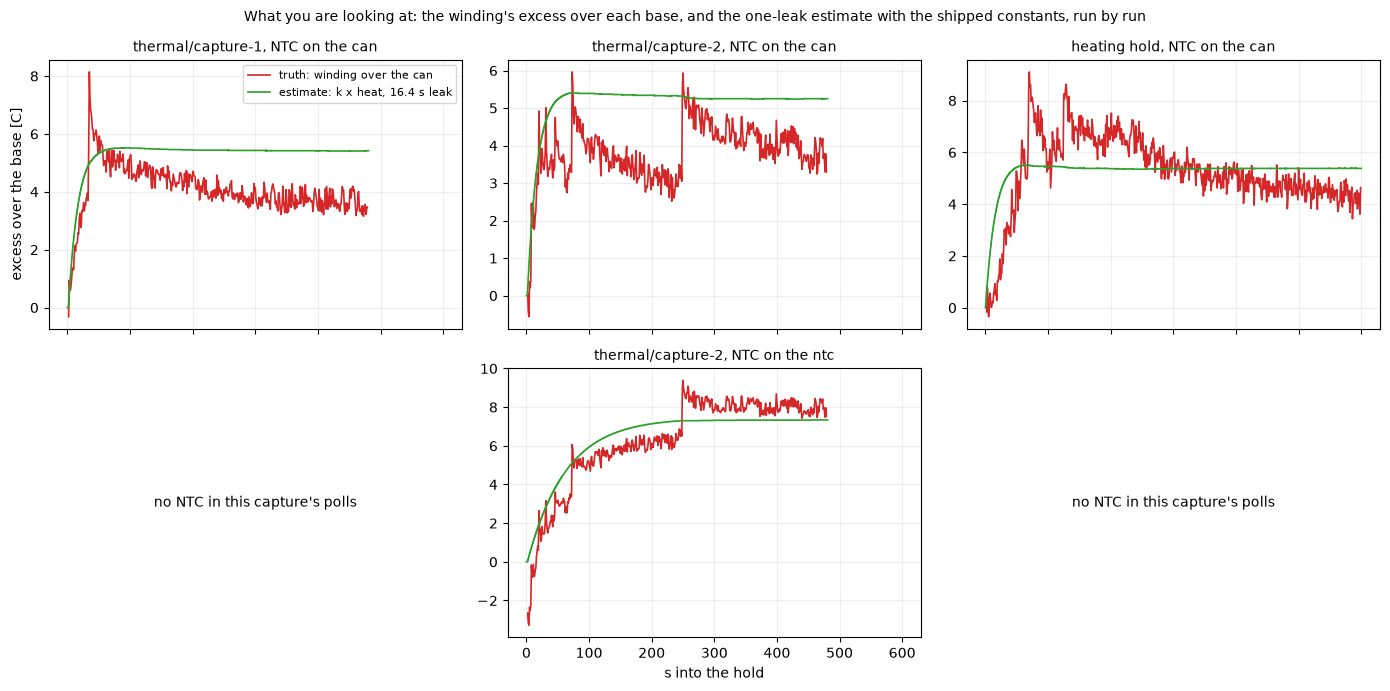

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for col, (name, R) in enumerate(RUNS.items()):
    for row, (base, shift, k) in enumerate((("can", CAN_SHIFT, K_CAN), ("ntc", NTC_SHIFT, K_NTC))):
        ax = axes[row, col]
        if R[base] is None:
            ax.text(0.5, 0.5, "no NTC in this capture's polls", ha="center", va="center", transform=ax.transAxes)
            ax.set_axis_off()
            continue
        x = R["tw"] - R[base]
        hq = i2t.heat(R["ig"].astype(np.int64), shift)
        est = i2t.rise_cc(hq, i2t.k_q16_of(k)) / 100                 # the kernel's integer rise
        ax.plot(R["tt"], x, color="tab:red", lw=1.2, label=f"truth: winding over the {base}")
        ax.plot(R["tg"], est, color="tab:green", lw=1.2, label=f"estimate: k x heat, {i2t.tau_s(shift):.1f} s leak")
        ax.set_title(f"{name}, NTC on the {base}", fontsize=10)
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel("excess over the base [C]")
            ax.legend(fontsize=8)
        if row == 1:
            ax.set_xlabel("s into the hold")
fig.suptitle("What you are looking at: the winding's excess over each base, and the one-leak estimate with the shipped "
             "constants, run by run", fontsize=10)
plt.tight_layout()
plt.show()

## 4. The grade

The signed error of the estimate with the shipped constants, over every run that can grade the
placement. Cold is the estimate under the copper reading, warm is over it.

In [8]:
rows = []
for name, R in RUNS.items():
    for base, shift, k in (("can", CAN_SHIFT, K_CAN), ("ntc", NTC_SHIFT, K_NTC)):
        if R[base] is None:
            continue
        x = R["tw"] - R[base]
        est = np.interp(R["tt"], R["tg"], i2t.rise_cc(i2t.heat(R["ig"].astype(np.int64), shift), i2t.k_q16_of(k))) / 100
        lo, hi, rms = i2t.grade(est, x)
        e = est - x
        late = R["tt"] >= 120
        rows.append({"run": name, "NTC on the": base, "tau s": i2t.tau_s(shift), "k_q16": i2t.k_q16_of(k),
                     "cold C": lo, "coldest at s": float(R["tt"][np.argmin(e)]), "warm C": hi,
                     "warmest at s": float(R["tt"][np.argmax(e)]), "rms C": rms,
                     "cold after 120 s": float(e[late].min()), "warm after 120 s": float(e[late].max())})
GRADE = pd.DataFrame(rows)
display(GRADE.round(2))
for base in ("can", "ntc"):
    g = GRADE[GRADE["NTC on the"] == base]
    print(f"NTC on the {base}: over the whole hold at most {-g['cold C'].min():.1f} C cold and {g['warm C'].max():.1f} C warm; "
          f"after 120 s at most {-g['cold after 120 s'].min():.1f} C cold and {g['warm after 120 s'].max():.1f} C warm")

,run,NTC on the,tau s,k_q16,cold C,coldest at s,warm C,warmest at s,rms C,cold after 120 s,warm after 120 s
0,thermal/capture-1,can,16.38,507,-3.16,35.0,2.25,473.0,1.40,0.46,2.25
1,thermal/capture-2,can,16.38,507,-1.12,20.0,2.81,232.0,1.47,-0.63,2.81
2,thermal/capture-2,ntc,65.54,710,-2.08,250.0,3.57,4.0,1.01,-2.08,1.45
3,heating hold,can,16.38,507,-3.61,70.0,3.62,18.0,1.22,-3.21,1.95


NTC on the can: over the whole hold at most 3.6 C cold and 3.6 C warm; after 120 s at most 3.2 C cold and 2.8 C warm
NTC on the ntc: over the whole hold at most 2.1 C cold and 3.6 C warm; after 120 s at most 2.1 C cold and 1.4 C warm


With the NTC on the can the cold extremes sit in the early peak of section 2, 20 to 70 s into the
holds, where the copper reads a rise the one leak does not follow. The warm extremes come late,
where the copper's excess falls back and the estimate holds its level. On the dev board the slow
leak reads warm in the first seconds (the integer heat leads the copper) and cold in the middle of
the hold, where the can's slow mode shows through. Through the whole of every run the estimate
stays inside 3.6 C either way, and about one contact step of that is in the truth, not the
estimate.

For a protection constant that is the band I would propose: the estimate never more than 5 C cold
or 5 C warm against the copper reading over a hold at the rating, for either placement. Five is
not an accuracy claim. It is the width the one-leak model holds on this motor with constants from
three holds, with a degree of room for the next unit and a contact step. The real protection
margin sits in `i_cont` itself, since the I2t fold holds the current at the rating whatever the
estimate reads.

## 5. Across torque-off gaps

A hold grades the rise. The out-and-back reps of notebook 19 grade the fall. Each rep holds at the
low stop for 150 s, then leaves with torque off for 240 s, 30 s, 240 s, 30 s and 240 s before five
more 60 s holds at the same stop, logging the current every 12 ms the whole way. The winding has no
resistance reading with torque off, but after a 240 s gap it sits at the can (notebook 19's $T^*$),
so the can less the rest offset, minus the NTC, is the truth excess at the first base of holds 1, 3
and 5. The 30 s gaps have no truth and are listed for the eye only.

In [9]:
rows = []
for c in ("oab/capture-1", "oab/capture-2"):
    log = tm.th_log(DS, c, "oab")
    m = tm.meter(DS, c)
    off = tm.rest_offset(tm.th_log(DS, c, "rest"), m)["offset"]
    t0 = log.t_unix.min()
    tg, ig = i2t.grid(log.t_unix.to_numpy() - t0, log.i.abs().to_numpy(), 0.0, log.t_unix.max() - t0)
    est = i2t.rise_cc(i2t.heat(ig.astype(np.int64), NTC_SHIFT), i2t.k_q16_of(K_NTC)) / 100
    for b in tm.bases(log).query("n == 0").itertuples():
        if b.hold == "hold0":
            continue
        gap = {"hold1": 240, "hold2": 30, "hold3": 240, "hold4": 30, "hold5": 240}[b.hold]
        truth = tm.can_at(m, b.t_unix) - off - b.t_ntc if gap == 240 else np.nan
        e = float(np.interp(b.t_unix - t0, tg, est))
        rows.append({"rep": c, "hold": b.hold, "gap before s": gap, "estimate excess C": e,
                     "truth T* - NTC C": truth, "error C": e - truth})
GAPS = pd.DataFrame(rows)
display(GAPS.round(2))

,rep,hold,gap before s,estimate excess C,truth T* - NTC C,error C
0,oab/capture-1,hold1,240,0.55,0.84,-0.29
1,oab/capture-1,hold2,30,3.20,NaN,NaN
2,oab/capture-1,hold3,240,0.50,0.89,-0.39
3,oab/capture-1,hold4,30,2.81,NaN,NaN
4,oab/capture-1,hold5,240,0.51,0.82,-0.31
5,oab/capture-2,hold1,240,0.54,0.65,-0.11
6,oab/capture-2,hold2,30,3.12,NaN,NaN
7,oab/capture-2,hold3,240,0.52,0.60,-0.08
8,oab/capture-2,hold4,30,3.06,NaN,NaN
9,oab/capture-2,hold5,240,0.52,0.14,0.38


After a 240 s gap the 65.5 s leak has let the heat fall to 2.5 % and the estimate sits half a
degree over the NTC, while the can-derived truth says the winding sits 0.1 to 0.9 C over it. The
errors are a few tenths either way, which is the rest offset's own uncertainty, not the
estimate's. After a 30 s gap the estimate still carries 3 C of the hold's rise, which is right in
direction, and there is no truth to say by how much.

## 6. What ships from this

The firmware keeps the I2t heat it already has, reads the NTC in centi-C as before, and adds the
rise. The host writes two constants per servo and board, and this table is what `ident write`
gets for the bench MG90 until the teardown refines it.

In [10]:
r_ohm = HOLDS["R_ref ohm"].mean()
ship = pd.DataFrame([
    {"NTC on the": "can (swap board)", "thermal_tau_ms": int(i2t.tau_s(CAN_SHIFT) * 1000), "shift": CAN_SHIFT,
     "th_rise_q016": i2t.k_q16_of(K_CAN), "k cC/count^2": K_CAN, "C/W it implies": K_CAN / (100 * r_ohm * board.a_per_count ** 2)},
    {"NTC on the": "board in room air (dev board)", "thermal_tau_ms": int(i2t.tau_s(NTC_SHIFT) * 1000), "shift": NTC_SHIFT,
     "th_rise_q016": i2t.k_q16_of(K_NTC), "k cC/count^2": K_NTC, "C/W it implies": K_NTC / (100 * r_ohm * board.a_per_count ** 2)},
]).set_index("NTC on the")
display(ship.round({"k cC/count^2": 5, "C/W it implies": 1}))
i_cont = 277                                                     # the bench MG90's 250 mA rating in counts
print(f"at i_cont {i_cont} counts the heat settles at {i_cont ** 2} counts^2: a rise of "
      f"{i2t.rise_cc([i_cont ** 2], i2t.k_q16_of(K_CAN))[0] / 100:.1f} C over the can, "
      f"{i2t.rise_cc([i_cont ** 2], i2t.k_q16_of(K_NTC))[0] / 100:.1f} C over the board NTC")

,thermal_tau_ms,shift,th_rise_q016,k cC/count^2,C/W it implies
NTC on the,,,,,
can (swap board),16384,10,507,0.00773,21.1
board in room air (dev board),65536,12,710,0.01084,29.5


at i_cont 277 counts the heat settles at 76729 counts^2: a rise of 5.9 C over the can, 8.3 C over the board NTC


The teardown changes one input. The winding's heat capacity sets how fast the first seconds of a
hold may rise, and with it known the early peak of section 2 can be split into real heat and brush
contact. If the contact share is as large as section 7 suspects, the truth excess over the can
gets smaller and so does $k$. That is a smaller rise constant, so the shipped one stays on the
warm side until then.

## 7. What is open

- **The first ten seconds rise too fast for the winding.** In capture-2 the copper reads 7 C up
  between 2 and 10 s at 0.26 W. Notebook 18's heat capacity bracket of 0.9 to 1.3 J/C allows 2 C in
  that time. Candidates: (a) brush contact resistance rising as the contact spot heats under
  current, which copper then reads as winding, (b) the 1 to 3 s reference window catching the
  contact still settling downward (the shipped thermometer's own note says every seated hold fell
  0.4 to 0.9 % through its first second), (c) a heat capacity well under the bracket. The teardown
  tells (c) from the rest. (a) from (b) wants a hold with the reference window at 5 to 7 s, which
  (b) predicts flattens the early peak and (a) does not.
- **Winding to can reads 15 to 21 C/W here, against 28 to 45 in notebook 18.** The same locked hold
  is in both. Notebook 18 took its number from the can's fitted dynamics with the winding's heat
  capacity tied to it. This notebook reads it straight off the winding's excess at the end of the
  hold. If the end excess carries a negative contact drift (the aggregate R falls 0.4 % over the
  last five minutes while the can still rises, candidate (a) above in reverse), the direct read is
  low and notebook 18 is nearer. A hold at half the current would halve the heat and leave the
  contact drift where it is. Until then the two brackets stand side by side.
- **The excess over the can falls after its early peak.** A two-node plant holds its fast node
  up. The same contact candidates cover it. A bead on a second spot of the can would say whether
  the can's own gradient is in it.
- **One run grades the dev board placement.** Capture-1 has no NTC in its polls. A second ident
  thermal hold with the NTC logged is the cheapest repeat, and the bench gate of the firmware band
  will be that run.
- **The cool-down has no copper truth.** The heating dataset's bursts every 60 s after its hold
  scatter 2 % of R, 5 C, as notebook 18 already found, so the fall is graded by the can alone
  (section 5). A locked hold with a short aggregate pulse every 30 s during the cool-down would read
  the winding's fall through the same ratio as the rise.

## Caveats

The truth is copper through a brush contact, so it carries the contact's 1 to 3 % of R, 2.5 to 8 C,
and the grade can only be as honest as that. The constants are one motor on one board and the
dev board's NTC is a board thermometer in room air, not a can thermometer. The swap board's NTC
will sit inside the case, nearer the can than this, and its own constants need its own hold once
the board exists. The leak is a power of two, so a user's `thermal_tau_ms` runs at the nearest
octave, up to a factor of 1.4 off what was written.

The estimate is for protection. Nothing in it reads the winding to a degree, and nothing in the
firmware claims to.

## What is next

The firmware strip, with this replay as the golden for its sim pin, then a heating hold on the bench
with the shipped estimate in the telemetry and this notebook's truth read over it. If you run the
hold on another servo, `oscnb.i2t` and the two loaders above are all it takes to get its constants.
Let me know what the teardown weighs.